In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 
import os
print(os.listdir('../data/raw'))


['Ecommerce_Fraud_Detection.csv.xlsx']


In [2]:
df = pd.read_excel('../data/raw/Ecommerce_Fraud_Detection.csv.xlsx')
df

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,transaction_time,shipping_distance_km,is_fraud
0,1,1,141,47,147.93,84.75,FR,FR,web,travel,0,1,1,1,2024-01-06T04:09:39Z,370.95,0
1,2,1,141,47,147.93,107.90,FR,FR,web,travel,0,0,0,0,2024-01-09T20:13:47Z,149.62,0
2,3,1,141,47,147.93,92.36,FR,FR,app,travel,1,1,1,1,2024-01-12T06:20:11Z,164.08,0
3,4,1,141,47,147.93,112.47,FR,FR,web,fashion,0,1,1,1,2024-01-15T17:00:04Z,397.40,0
4,5,1,141,47,147.93,132.91,FR,US,web,electronics,0,1,1,1,2024-01-17T01:27:31Z,935.28,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299690,299691,6000,996,45,27.93,34.07,ES,ES,web,grocery,0,1,1,0,2024-09-29T04:40:54Z,218.55,0
299691,299692,6000,996,45,27.93,68.56,ES,ES,app,travel,0,1,1,1,2024-10-03T08:49:02Z,185.55,0
299692,299693,6000,996,45,27.93,25.02,ES,ES,app,fashion,0,1,1,1,2024-10-26T07:40:38Z,33.50,0
299693,299694,6000,996,45,27.93,23.92,ES,ES,web,gaming,0,0,0,0,2024-10-27T09:31:56Z,71.75,0


In [3]:
print(df['channel'].unique())

['web' 'app']


In [4]:
df.head()

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,transaction_time,shipping_distance_km,is_fraud
0,1,1,141,47,147.93,84.75,FR,FR,web,travel,0,1,1,1,2024-01-06T04:09:39Z,370.95,0
1,2,1,141,47,147.93,107.90,FR,FR,web,travel,0,0,0,0,2024-01-09T20:13:47Z,149.62,0
2,3,1,141,47,147.93,92.36,FR,FR,app,travel,1,1,1,1,2024-01-12T06:20:11Z,164.08,0
3,4,1,141,47,147.93,112.47,FR,FR,web,fashion,0,1,1,1,2024-01-15T17:00:04Z,397.40,0
4,5,1,141,47,147.93,132.91,FR,US,web,electronics,0,1,1,1,2024-01-17T01:27:31Z,935.28,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299695 entries, 0 to 299694
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   transaction_id           299695 non-null  int64  
 1   user_id                  299695 non-null  int64  
 2   account_age_days         299695 non-null  int64  
 3   total_transactions_user  299695 non-null  int64  
 4   avg_amount_user          299695 non-null  float64
 5   amount                   299695 non-null  float64
 6   country                  299695 non-null  object 
 7   bin_country              299695 non-null  object 
 8   channel                  299695 non-null  object 
 9   merchant_category        299695 non-null  object 
 10  promo_used               299695 non-null  int64  
 11  avs_match                299695 non-null  int64  
 12  cvv_result               299695 non-null  int64  
 13  three_ds_flag            299695 non-null  int64  
 14  tran

# EDA

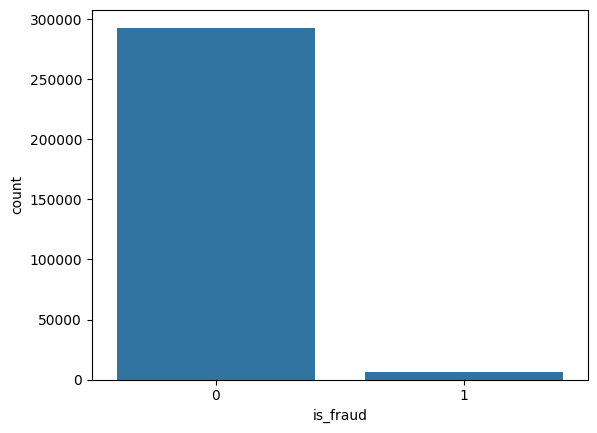

In [6]:
# fraud rate visuailize
sns.countplot(x="is_fraud", data=df)
plt.show()

In [7]:
# country mismatch vs fraud
df['country_mismatch'] = (df['country'] != df['bin_country']).astype(int)
print(df.groupby('country_mismatch')['is_fraud'].mean())

country_mismatch
0    0.014263
1    0.112769
Name: is_fraud, dtype: float64


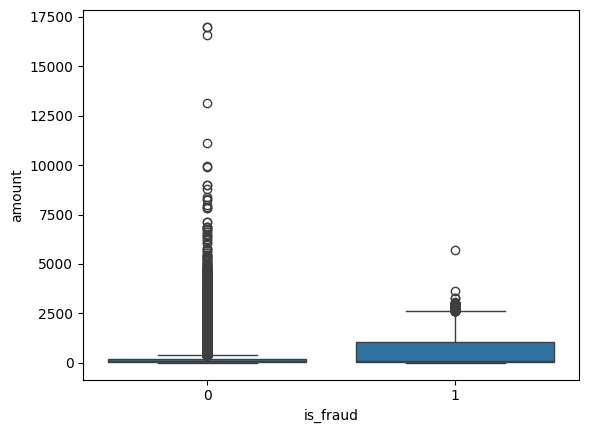

In [8]:
# amount vs fraud
sns.boxplot(x='is_fraud', y='amount', data=df)
plt.show()

In [9]:
# verification flags vs fraud
print(df.groupby('avs_match')['is_fraud'].mean())
print(df.groupby('cvv_result')['is_fraud'].mean())
print(df.groupby('three_ds_flag')['is_fraud'].mean())

avs_match
0    0.096661
1    0.007641
Name: is_fraud, dtype: float64
cvv_result
0    0.106058
1    0.009745
Name: is_fraud, dtype: float64
three_ds_flag
0    0.067521
1    0.009582
Name: is_fraud, dtype: float64


<Axes: xlabel='hour'>

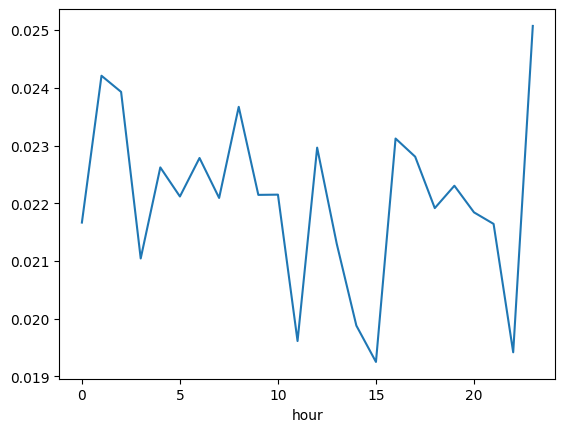

In [10]:
# time-of-time pattern
df['transaction_time'] = pd.to_datetime(df['transaction_time'])
df['hour'] = df['transaction_time'].dt.hour
df.groupby('hour')['is_fraud'].mean().plot(kind='line')

# statistical Analysis

In [11]:
from scipy.stats import chi2_contingency, mannwhitneyu
import numpy as np

In [12]:
# --- 1. chi-square test: categorical flags vs fraud

for col in ['avs_match','cvv_result','three_ds_flag','country_mismatch']:
    contingency = pd.crosstab(df[col], df['is_fraud'])
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    print(f"{col}: chi2={chi2:.2f}, p_value={p_value:.2e}",
            "-> SIGNIFICANT" if p_value < 0.05 else "-> not significant")

avs_match: chi2=14939.44, p_value=0.00e+00 -> SIGNIFICANT
cvv_result: chi2=14366.82, p_value=0.00e+00 -> SIGNIFICANT
three_ds_flag: chi2=7878.10, p_value=0.00e+00 -> SIGNIFICANT
country_mismatch: chi2=9822.70, p_value=0.00e+00 -> SIGNIFICANT


In [13]:
# ---- 2. Mann-Whitney U test: amount vs fraud ----

fraud_amounts = df[df['is_fraud'] == 1]['amount']
legit_amounts = df[df['is_fraud'] == 0]['amount']
stat, p_value = mannwhitneyu(fraud_amounts, legit_amounts, alternative='two-sided')
print(f"\n Amount Mann-Whitney U test: p-value={p_value:.2e}",
        "-> SIGNIFICANT" if p_value < 0.05 else "-> not significant")


 Amount Mann-Whitney U test: p-value=1.03e-14 -> SIGNIFICANT


In [14]:
# ---- 3. Bayes' Theorem: P(fraud | CVV fail) ----
p_fraud = df['is_fraud'].mean()   # P(fraud)
p_cvv_fail_given_fraud = (df[df['is_fraud']==1]['cvv_result']==0).mean()  # P(cvv fail | fraud)
p_cvv_fail = (df['cvv_result']== 0).mean()  # P(cvv fail)

p_fraud_given_cvv_fail = (p_cvv_fail_given_fraud * p_fraud) / p_cvv_fail
print(f"\n P(Fraud) overall = {p_fraud:.4f}")
print(f"P(fraud | CVV fail) = {p_fraud_given_cvv_fail:.4f}")
print(f"-> CVV failure increase fraud risk by {p_fraud_given_cvv_fail/p_fraud:.1f}x")


 P(Fraud) overall = 0.0221
P(fraud | CVV fail) = 0.1061
-> CVV failure increase fraud risk by 4.8x


In [15]:
# ---- 4. Confidence Interval for fraud rate ----
n = len(df)
p = df['is_fraud'].mean()
se = np.sqrt(p * (1-p) / n)
ci_low, ci_high = p - 1.96*se, p + 1.96*se
print(f"\n Fraud rate 95% CI: [{ci_low:.4f}, {ci_high:.4f}]")


 Fraud rate 95% CI: [0.0215, 0.0226]


# Feature Engineering

In [16]:
# 1. ID columns drop 
df.drop(columns=['transaction_id','user_id'], inplace=True)

In [17]:
# 2. country_mismatch , raw_columns
df.drop(columns=['country', 'bin_country'], inplace=True)

In [18]:
# 3. transaction_time drop 
df.drop(columns=['transaction_time'], inplace=True)

In [19]:
print(df['channel'].unique())

['web' 'app']


In [20]:
# 4. categorical encoding
from sklearn.preprocessing import LabelEncoder
import joblib
cat_cols = ['channel','merchant_category']
encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le 

joblib.dump(encoders, "../models/encoders.pkl")


['../models/encoders.pkl']

In [21]:
# 5. Numeric scaling
from sklearn.preprocessing import LabelEncoder, StandardScaler
import joblib

scaler = StandardScaler()
num_cols = ['account_age_days','total_transactions_user','avg_amount_user','amount','shipping_distance_km','hour']
df[num_cols] = scaler.fit_transform(df[num_cols])
joblib.dump(scaler,"../models/scaler.pkl")
df.head()

,account_age_days,total_transactions_user,avg_amount_user,amount,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,shipping_distance_km,is_fraud,country_mismatch,hour
0,-1.584794,-0.61464,-0.001063,-0.301100,1,4,0,1,1,1,0.032504,0,0,-1.084390
1,-1.584794,-0.61464,-0.001063,-0.225674,1,4,0,0,0,0,-0.485020,0,0,1.225727
2,-1.584794,-0.61464,-0.001063,-0.276305,0,4,1,1,1,1,-0.451209,0,0,-0.795625
3,-1.584794,-0.61464,-0.001063,-0.210785,1,1,0,1,1,1,0.094350,0,0,0.792580
4,-1.584794,-0.61464,-0.001063,-0.144189,1,0,0,1,1,1,1.352045,0,1,-1.517537


In [22]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix
import joblib

In [23]:
# 1. split
X = df.drop('is_fraud', axis=1)
y = df['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [24]:
# 2. imbalance weight 
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", scale_pos_weight)

scale_pos_weight: 44.32249527410208


In [25]:
# 3. Train
model = XGBClassifier(eval_metric='logloss', scale_pos_weight= scale_pos_weight)
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [26]:
# 4. Evalute
preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, preds))
print("ROC-AUC:", roc_auc_score(y_test, probs))
print("PR-AUC:", average_precision_score(y_test, probs))
print("Confusion Matrix:\n", confusion_matrix(y_test, preds))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     58617
           1       0.48      0.86      0.61      1322

    accuracy                           0.98     59939
   macro avg       0.74      0.92      0.80     59939
weighted avg       0.99      0.98      0.98     59939

ROC-AUC: 0.973956685978935
PR-AUC: 0.8574412794077225
Confusion Matrix:
 [[57368  1249]
 [  185  1137]]


In [27]:
# 5. save 
joblib.dump(model, "../models/fraud_model.pkl")

['../models/fraud_model.pkl']

# Probanility Calibration

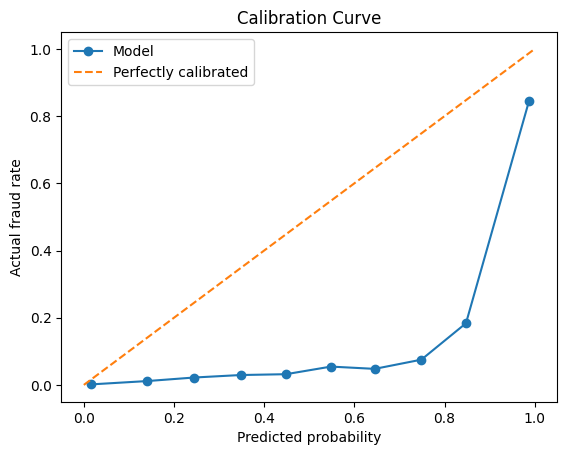

Brier Score: 0.019449636340141296


In [28]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Calibration curve
prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10)

plt.plot(prob_pred, prob_true, marker='o', label='Model')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated')
plt.xlabel("Predicted probability")
plt.ylabel("Actual fraud rate")
plt.title("Calibration Curve")
plt.legend()
plt.show()

# Brier Score
print("Brier Score:", brier_score_loss(y_test, probs))

In [29]:
from sklearn.calibration import CalibratedClassifierCV


In [30]:
# 1-2. Calibrate + train
calibrated_model = CalibratedClassifierCV(model, method='isotonic', cv=5)
calibrated_model.fit(X_train, y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","XGBClassifier...ree=None, ...)"
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...00257A115DD30>, 

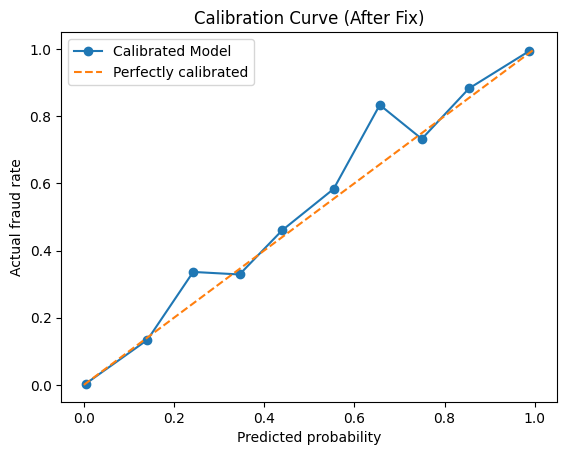

New Brier Score: 0.005687009236653291


In [31]:
# 3. New calibration plot
calibrated_probs = calibrated_model.predict_proba(X_test)[:, 1]
prob_true_cal, prob_pred_cal = calibration_curve(y_test, calibrated_probs, n_bins=10)

plt.plot(prob_pred_cal, prob_true_cal, marker='o', label='Calibrated Model')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated')
plt.xlabel("Predicted probability")
plt.ylabel("Actual fraud rate")
plt.title("Calibration Curve (After Fix)")
plt.legend()
plt.show()

print("New Brier Score:", brier_score_loss(y_test, calibrated_probs))

In [32]:
# 4. Compare recall/precision
calibrated_preds = calibrated_model.predict(X_test)
print(classification_report(y_test, calibrated_preds))
print("Confusion Matrix:\n", confusion_matrix(y_test, calibrated_preds))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00     58617
           1       0.95      0.74      0.83      1322

    accuracy                           0.99     59939
   macro avg       0.97      0.87      0.92     59939
weighted avg       0.99      0.99      0.99     59939

Confusion Matrix:
 [[58566    51]
 [  341   981]]


In [33]:
# 5. Save (replaces old model)
joblib.dump(calibrated_model, "../models/fraud_model.pkl")

['../models/fraud_model.pkl']

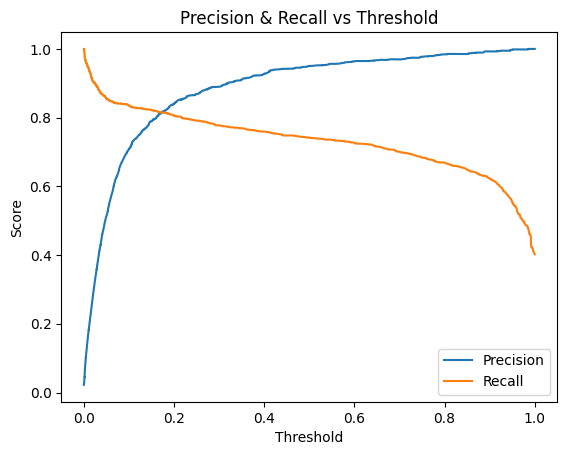

Threshold = 0.3
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     58617
           1       0.89      0.78      0.83      1322

    accuracy                           0.99     59939
   macro avg       0.94      0.89      0.91     59939
weighted avg       0.99      0.99      0.99     59939

Confusion Matrix:
 [[58490   127]
 [  294  1028]]


In [34]:
from sklearn.metrics import precision_recall_curve

# 1. Saare thresholds nikalo
precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated_probs)

# 2. Plot
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision & Recall vs Threshold")
plt.legend()
plt.show()

# 3-4. Custom threshold try karo (0.3 se shuru karo, adjust kar sakte ho)
custom_threshold = 0.3
custom_preds = (calibrated_probs >= custom_threshold).astype(int)

print(f"Threshold = {custom_threshold}")
print(classification_report(y_test, custom_preds))
print("Confusion Matrix:\n", confusion_matrix(y_test, custom_preds))

In [35]:
df.columns

Index(['account_age_days', 'total_transactions_user', 'avg_amount_user',
       'amount', 'channel', 'merchant_category', 'promo_used', 'avs_match',
       'cvv_result', 'three_ds_flag', 'shipping_distance_km', 'is_fraud',
       'country_mismatch', 'hour'],
      dtype='object')

In [36]:
print(encoders.keys())
for col, le in encoders.items():
    print(col, "->", le.classes_[:5])

dict_keys(['channel', 'merchant_category'])
channel -> ['app' 'web']
merchant_category -> ['electronics' 'fashion' 'gaming' 'grocery' 'travel']
